# Week 6 Homework: Your Answers vs. Your Vibe-Coded Dashboard

**Week 4 dashboard link:** _(https://aqureshi106-movielens.streamlit.app/)_

---

Two weeks ago you vibe-coded a MovieLens dashboard before you had the tools to judge it. Since then you've had the stats lecture (Week 5) and this week's EDA lecture. Now you do it the real way: answer the same 4 questions yourself, by hand, then audit the dashboard against your own work.

**Ground rules**

- 🚫 **No AI for code or answers in Parts 1 and 2.** Lecture notebooks, pandas/seaborn docs, Google, and Stack Overflow are all fair game. Write Part 3 in your own words too.
- 🔒 **Lock in before you peek.** Finish Parts 1 and 2 (answers written down) *before* you open your dashboard. If you look first, you'll anchor on its numbers and the comparison is worthless.
- 🔢 **Show your numbers.** Every answer needs actual values (counts, averages, titles), not just a vibe.
- ✏️ Written answers go in markdown cells (double-click to edit, Shift+Enter to render). Most are 2 to 4 sentences. Short and specific beats long and vague.

## The data

`movie_ratings.csv` has one row per rating: 100,000 ratings from 943 users on 1,682 movies.

- `user_id`, `movie_id`: who rated, which movie
- `rating`: 1 to 5 stars
- `timestamp`, `rating_year`: when the rating was given
- `age`, `gender`, `occupation`, `zip_code`: the rater
- `title`: movie title, with release year in parentheses
- `year`, `decade`: the movie's release year and decade
- `genres`: all of the movie's genres in one string, separated by the pipe character (a movie can have several)

## Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Works whether this notebook sits in the week folder or inside exercise/
data_path = next(p for p in ["data/movie_ratings.csv", "../data/movie_ratings.csv"] if Path(p).exists())
df = pd.read_csv(data_path)
df.head()

,user_id,movie_id,rating,timestamp,age,gender,occupation,zip_code,title,year,decade,genres,rating_year
0,196,242,3,1997-12-04 15:55:49,49,M,writer,55105,Kolya (1996),1996.0,1990.0,Comedy,1997
1,186,302,3,1998-04-04 19:22:22,39,F,executive,00000,L.A. Confidential (1997),1997.0,1990.0,Crime|Film-Noir|Mystery|Thriller,1998
2,22,377,1,1997-11-07 07:18:36,25,M,writer,40206,Heavyweights (1994),1994.0,1990.0,Children|Comedy,1997
3,244,51,2,1997-11-27 05:02:03,28,M,technician,80525,Legends of the Fall (1994),1994.0,1990.0,Drama|Romance|War|Western,1997
4,166,346,1,1998-02-02 05:33:16,47,M,educator,55113,Jackie Brown (1997),1997.0,1990.0,Crime|Drama,1998


---
# Part 1: Methodology

## 1.1 Know your data first

Before answering anything, check what you're working with: shape, column types, missing values, duplicate rows, and the range of the numeric columns.

In [2]:
# Data checks
print('Shape:', df.shape)
print('\nColumn types:')
display(df.dtypes.rename('dtype').to_frame())
print('\nMissing values:')
display(df.isna().sum().rename('missing').to_frame())
print('\nDuplicate rows:', df.duplicated().sum())
print('\nNumeric ranges:')
display(df.select_dtypes(include='number').agg(['min', 'max']).T)


Shape: (100000, 13)

Column types:


,dtype
user_id,int64
movie_id,int64
rating,int64
timestamp,str
age,int64
gender,str
occupation,str
zip_code,str
title,str
year,float64



Missing values:


,missing
user_id,0
movie_id,0
rating,0
timestamp,0
age,0
gender,0
occupation,0
zip_code,0
title,0
year,30



Duplicate rows: 0

Numeric ranges:


,min,max
user_id,1.0,943.0
movie_id,1.0,1682.0
rating,1.0,5.0
age,7.0,73.0
year,1922.0,1998.0
decade,1920.0,1990.0
rating_year,1997.0,1998.0


**✏️ Data notes:** _(What did you find? Anything missing, duplicated, or surprising? What did you do about it, and why?)_

## 1.2 Decide before you chart

In Week 4 the questions were ambiguous on purpose. This is where *you* commit to an interpretation. Fill it in now, and update it if you change your mind while working (just say so).

**Q1 Genre breakdown**
- What you have to decide: What am I counting, ratings or movies? How do I handle movies that have several genres?
- My choice: Count rating by genre. For movies with multiple genres, splitting the genre string and count the rating once under each listed genre will work.
- Why: Each row represents one rating, so this measures how much rating activity each genre received.

**Q2 Genre satisfaction**
- What you have to decide: "Average rating" of what? How do I treat genres that have very little data?
- My choice: I will calculate the mean of all ratings within each genre. I will only compare genres with at least 50 ratings and will show the rating count along with each mean.
- Why: A genre’s average should represent the ratings people actually gave to movies in that genre. The minimum of 50 ratings reduces the chance that a genre appears highly rated because of only a few observations, and showing the count gives context for each average.

**Q3 Ratings over time**
- What you have to decide: Is every year backed by the same amount of data? What do I do with movies that have no release year?
- My choice: I will group ratings by the movie’s release year and calculate the average rating and number of ratings for each year.
- Why: This shows how ratings differ across movies released in different years.

**Q4 Best movies**
- What you have to decide: What is a movie's rating (the mean of what)? Is "at least 50" ≥ or >? What if there's a tie?
- My choice: A movie’s rating will be the mean of all ratings it received.
- Why: To average all ratings gives one comparable score per movie, while requiring at least 50 ratings prevents a movie with only a few ratings from appearing among the best. 

---
# Part 2: Results (by hand, no AI)

Answer each question with a chart or table **and** a written answer with real numbers. Pick the chart type yourself and be ready to defend it in Part 3. Add as many code cells as you need.

## Q1. Genre breakdown

**What's the distribution of genres among the movies that were rated?**

<details>
<summary>Stuck on movies with several genres? Hint</summary>

`genres` is one string like `Crime|Film-Noir|Mystery|Thriller`. To get one row per genre:

```python
genre_df = df.assign(genre=df['genres'].str.split('|')).explode('genre')
```

Heads up: after this, a movie with 3 genres takes up 3 rows. Think about what that does to anything you count or average. Exploding is fine for "how often does a genre show up", but be careful calling the result "market share" (the percentages add up to more than 100%).
</details>

Total genre assignments: 212,595
Top 10 genres by number of ratings:


,rating_count
genre,
Drama,39895
Comedy,29832
Action,25589
Thriller,21872
Romance,19461
Adventure,13753
Sci-Fi,12730
War,9398
Crime,8055


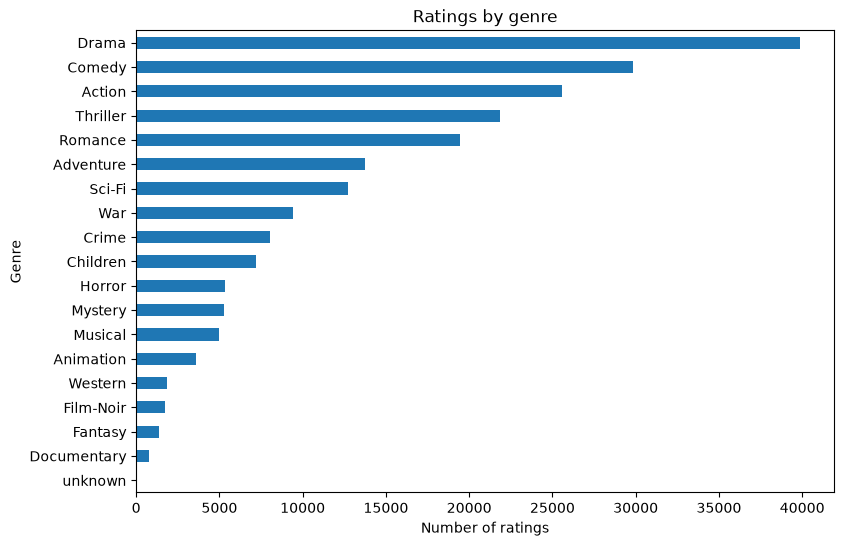

In [3]:
# Q1: Count rating rows by genre. A multi-genre movie contributes one count to each listed genre.
genre_df = df.assign(genre=df['genres'].str.split('|')).explode('genre')
genre_counts = genre_df['genre'].value_counts().sort_values(ascending=False)

print(f"Total genre assignments: {genre_counts.sum():,}")
print("Top 10 genres by number of ratings:")
display(genre_counts.head(10).rename('rating_count').to_frame())

genre_counts.sort_values().plot(kind='barh', figsize=(9, 6), title='Ratings by genre')
plt.xlabel('Number of ratings')
plt.ylabel('Genre')
plt.show()


**✏️ My answer (with numbers):** I counted rating rows by genre after splitting multi-genre movies. Drama was the largest genre with **39,895 ratings**, followed by Comedy (**29,832**) and Action (**25,589**). Because a movie can have more than one genre, the genre counts add up to **212,595 genre assignments**, not 100,000 unique ratings; therefore, these are counts of genre appearances, not market shares.

## Q2. Genre satisfaction

**Which genres have the highest average rating? Which have the lowest?**

Show how much data is behind each average (for example, the count next to it). An average of 10 ratings and an average of 10,000 ratings are not the same kind of evidence.

,rating_count,movie_count,mean_rating
genre,,,
Film-Noir,1733,24,3.922
War,9398,71,3.816
Drama,39895,725,3.687
Documentary,758,50,3.673
Mystery,5245,61,3.638
Crime,8055,109,3.632
Romance,19461,247,3.622
Western,1854,27,3.613
Animation,3605,42,3.577


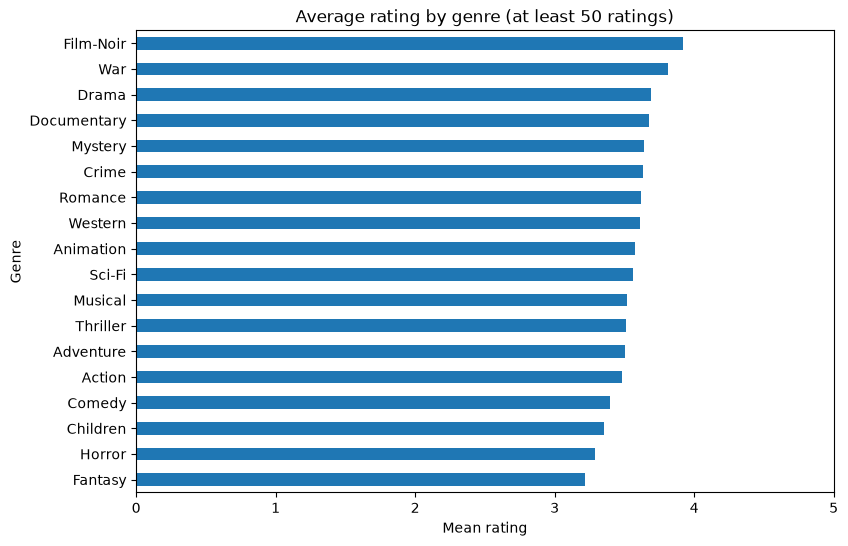

In [4]:
# Q2: Calculate the mean rating and sample size for each genre.
# Genres with fewer than 50 ratings are excluded from the comparison.
genre_summary = genre_df.groupby('genre').agg(
    rating_count=('rating', 'size'),
    movie_count=('movie_id', 'nunique'),
    mean_rating=('rating', 'mean')
).query('rating_count >= 50').sort_values('mean_rating', ascending=False)

display(genre_summary.round({'mean_rating': 3}))
genre_summary['mean_rating'].sort_values().plot(kind='barh', figsize=(9, 6), title='Average rating by genre (at least 50 ratings)')
plt.xlabel('Mean rating')
plt.ylabel('Genre')
plt.xlim(0, 5)
plt.show()


**✏️ My answer (with numbers):** Using a minimum of 50 ratings, Film-Noir had the highest average rating at **3.922** from **1,733 ratings across 24 movies**. Fantasy had the lowest average at **3.215** from **1,352 ratings across 22 movies**. I included the counts because averages based on different amounts of data should not be treated as equally strong evidence.

## Q3. Ratings over time

**How has the mean rating changed across movie release years?**

Show how many ratings each year is based on, alongside the trend.

,rating_count,mean_rating
year,,
1922.0,54,3.556
1926.0,2,3.000
1930.0,18,3.778
1931.0,44,4.000
1932.0,12,3.833
...,...,...
1994.0,9034,3.420
1995.0,12389,3.415
1996.0,18744,3.311


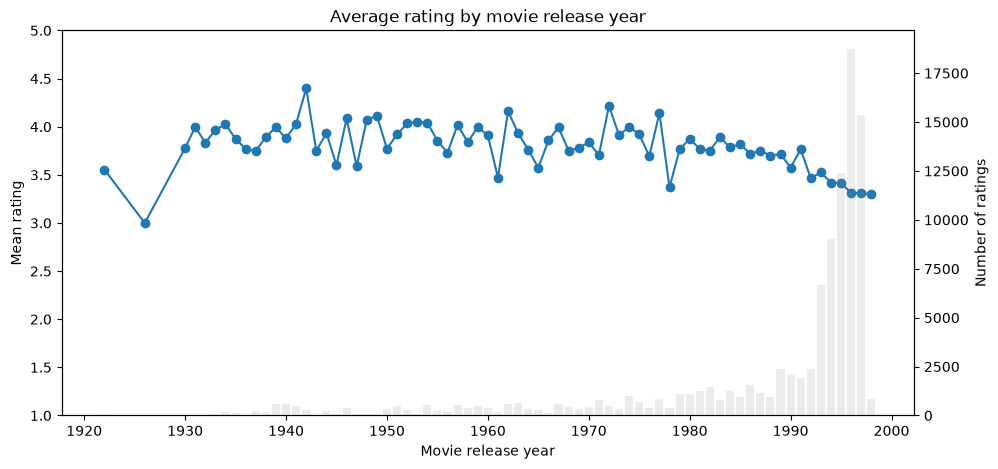

In [5]:
# Q3: Group by movie release year. Rows with missing release years are left out.
year_summary = (
    df.dropna(subset=['year'])
      .groupby('year')['rating']
      .agg(rating_count='size', mean_rating='mean')
      .sort_index()
)
display(year_summary.round({'mean_rating': 3}))

fig, ax1 = plt.subplots(figsize=(11, 5))
ax1.plot(year_summary.index, year_summary['mean_rating'], marker='o', linewidth=1.5)
ax1.set(title='Average rating by movie release year', xlabel='Movie release year', ylabel='Mean rating', ylim=(1, 5))
ax2 = ax1.twinx()
ax2.bar(year_summary.index, year_summary['rating_count'], alpha=0.15, color='gray', width=0.8)
ax2.set_ylabel('Number of ratings')
plt.show()


**✏️ My answer (with numbers):** The mean rating varies considerably across release years rather than following a steady increase or decrease. The yearly means range from **3.000 in 1926** (only **2 ratings**) to **4.398 in 1942** (**261 ratings**). Recent years have much more data, including **18,744 ratings in 1996**, while early years often have very small samples, so the trend is not equally reliable across the timeline. I excluded the 30 rows with missing release years.

## Q4. Best movies, with a floor

**What are the 5 best-rated movies that have at least 50 ratings? What changes if you raise the floor to 150?**

In [6]:
# Q4: Rank movies by their mean rating at two minimum-rating floors.
movie_summary = df.groupby(['movie_id', 'title'])['rating'].agg(
    rating_count='size',
    mean_rating='mean'
)

def top_movies(min_ratings):
    return movie_summary.query('rating_count >= @min_ratings').sort_values(
        ['mean_rating', 'title'], ascending=[False, True]
    ).head(5).round({'mean_rating': 3})

top_50 = top_movies(50)
top_150 = top_movies(150)
print('Top five with at least 50 ratings:')
display(top_50)
print('Top five with at least 150 ratings:')
display(top_150)


Top five with at least 50 ratings:


,,rating_count,mean_rating
movie_id,title,,
408,"Close Shave, A (1995)",112,4.491
318,Schindler's List (1993),298,4.466
169,"Wrong Trousers, The (1993)",118,4.466
483,Casablanca (1942),243,4.457
114,Wallace & Gromit: The Best of Aardman Animation (1996),67,4.448


Top five with at least 150 ratings:


,,rating_count,mean_rating
movie_id,title,,
318,Schindler's List (1993),298,4.466
483,Casablanca (1942),243,4.457
64,"Shawshank Redemption, The (1994)",283,4.445
603,Rear Window (1954),209,4.388
12,"Usual Suspects, The (1995)",267,4.386


**✏️ My answer (with numbers):** With at least 50 ratings, the top five were **A Close Shave (4.491, 112 ratings)**, **Schindler's List (4.466, 298)**, **The Wrong Trousers (4.466, 118)**, **Casablanca (4.457, 243)**, and **Wallace & Gromit: The Best of Aardman Animation (4.448, 67)**. With at least 150 ratings, the list was **Schindler's List (4.466, 298)**, **Casablanca (4.457, 243)**, **The Shawshank Redemption (4.445, 283)**, **Rear Window (4.388, 209)**, and **The Usual Suspects (4.386, 267)**. Raising the floor removed the three movies with fewer than 150 ratings and replaced them with movies supported by larger samples, showing why a rating floor matters.

> 🔒 **Stop here.** Parts 1 and 2 should be completely filled in before you open your dashboard.

---
# Part 3: Analysis

Now open your Week 4 dashboard.

## 3.1 How the dashboard got built

The build log records one initial prompt rather than two separate prompts. I am not inventing a second prompt; I used the documented prompt and the later visual-QA notes.

**Prompt 1**
- **What I asked:** I asked for a professional MovieLens dashboard, beginning with data profiling, checking missing values and duplicates, identifying ambiguous choices, selecting defensible aggregations and charts, testing the analytical logic, reviewing the rendered dashboard, and fixing visual problems.
- **AI's first attempt:** The first implementation separated the dashboard UI from the data-cleaning and analytical logic, used overlapping genre counts, pooled ratings for genre averages, release year for the time question, and top-five movie lists with 50- and 150-rating floors.
- **What I changed (or accepted without checking):** I accepted the main analytical choices after reviewing the reasoning. The build log then records visual-QA fixes: breaking Q3 lines across missing years, adding a year/decade view, matching Q4 axis scales, fixing duplicate Q2 tick labels, and making Q1 captions honest when filters were active.

**Prompt 2**
- **What I asked:** No second prompt is preserved in the build log. The next documented work is the visual-QA and refinement pass.
- **AI's first attempt:** The first dashboard version had issues later recorded in the build log, including misleading line connections across missing years and inconsistent comparison axes.
- **What I changed (or accepted without checking):** I accepted the documented fixes because they made missing data and comparisons clearer instead of hiding them.

## 3.2 Compare the answers

The dashboard and my notebook use the same main definitions, so the results are the same in principle. The dashboard's documented data-cleaning step differs from this raw-data notebook: it resolves duplicate movie records, recovers four missing years from titles, and removes the unusable `unknown` record.

**Q1**
- **Dashboard says:** Drama is the most common genre, at about 43% of the cleaned movie records.
- **I say:** Drama has **39,895 rating assignments**, followed by Comedy (**29,832**) and Action (**25,589**).
- **Same?** partly.
- **Why:** Both identify Drama as the largest genre, but the dashboard describes movie-genre appearances while my result counts rating rows. Multi-genre movies can appear in several categories, so neither is an exclusive market share.

**Q2**
- **Dashboard says:** Film-Noir is highest at about **3.92**, and Fantasy is lowest at about **3.22**, using pooled ratings.
- **I say:** Film-Noir is **3.922** from **1,733 ratings**, and Fantasy is **3.215** from **1,352 ratings**.
- **Same?** yes, approximately.
- **Why:** Both use the mean of individual ratings. Small differences can come from the dashboard's cleaning of duplicate and missing-year records.

**Q3**
- **Dashboard says:** The dashboard uses movie release year, adds confidence intervals, and defaults to a 50-rating minimum; its decade view makes the overall decline easier to see.
- **I say:** Release-year means range from **3.000 in 1926** (2 ratings) to **4.398 in 1942** (261 ratings), and recent years have much more data.
- **Same?** partly.
- **Why:** The interpretation is the same, but the dashboard filters sparse years by default and cleans the release-year field. My notebook shows the complete raw-data range and explicitly reports the sample sizes.

**Q4**
- **Dashboard says:** The 50-rating list includes several Wallace & Gromit/Aardman movies; raising the floor to 150 removes them and brings in The Shawshank Redemption, Rear Window, and The Usual Suspects.
- **I say:** The 50-rating list includes A Close Shave, The Wrong Trousers, and Wallace & Gromit: The Best of Aardman Animation, while the 150-rating list replaces them with movies supported by larger samples.
- **Same?** yes, approximately.
- **Why:** Both use ordinary movie means and apply the thresholds as at least 50 and at least 150 ratings. The dashboard's duplicate-record cleaning can change exact counts slightly.

**Two causes of differences:** Q1 differs because one result counts rating assignments and the dashboard summarizes cleaned movie-genre records. Q3 differs because the dashboard applies a 50-rating display filter and cleans missing years, while my notebook keeps every nonmissing raw release year so that the uncertainty is visible.

## 3.3 Chart choices

**Q1**
- **Dashboard:** Sorted horizontal bar chart.
- **I used:** Sorted horizontal bar chart.
- **Better choice:** They are equally clear. Horizontal bars make the long genre labels readable, and sorting makes the largest categories easy to find.

**Q2**
- **Dashboard:** Diverging bar chart centered on the overall mean, with confidence intervals.
- **I used:** Sorted horizontal bar chart with the mean rating, rating count, and movie count in the table.
- **Better choice:** The dashboard communicates uncertainty better because it shows confidence intervals. My table is simpler and makes the sample sizes easy to check.

**Q3**
- **Dashboard:** Release-year line chart with confidence intervals and a year/decade switch.
- **I used:** A release-year line chart with rating counts shown as gray bars on a second axis.
- **Better choice:** My chart makes sample-size differences visible, while the dashboard's decade option communicates the broad trend more clearly. Both are better than a line chart that connects across missing years.

**Q4**
- **Dashboard:** Two side-by-side horizontal bar charts with shared x-axis limits for the 50- and 150-rating floors.
- **I used:** Two sorted result tables showing movie title, mean rating, and rating count.
- **Better choice:** The dashboard is better for comparing the two rankings because the shared axes make movement and dropouts easy to see. My tables provide the exact values and sample sizes.


## 3.4 What can this data actually tell you?

**Answer at least 3 of these 5**, using your own results as evidence.

**1. Who is in this data?** Check the fewest and the most ratings any single user has given (`df.groupby('user_id').size()`), and look at `rating_year`. What kind of person ends up in a dataset like this, and who is missing? How might that tilt your Q2 answer? *(Week 5: sampling bias)*

**2. How sure are you about the bottom genre?** Take the lowest-rated genre from your Q2. How many ratings *and* how many distinct movies is it built on? Estimate a rough 95% interval: mean ± 1.96 × std / √n. Would you bet it's truly the worst genre? *(Week 5: standard error and confidence intervals. Also ask yourself: are 5,000 ratings of the same handful of movies really 5,000 independent pieces of evidence? Remember the one-row-per-model lesson from last week's homework.)*

**3. What can Q3 really say about time?** How many different values does `rating_year` have? So can this data tell you whether people's taste changed over time? What does your Q3 trend actually describe instead? Why might an old movie in this dataset score higher than a recent one? *(Think: who rates a 1940s film in 1997, and which old movies are even in the data?)*

**4. Does "average" depend on how you average?** Recompute Q2 two ways: (a) average over all ratings, (b) average each movie first, then average the movies within each genre. Does the top genre change? "Which genre do *people* like most?" and "which genre has the best *movies*?" are different questions. *(Week 5: confounding, Simpson's paradox)*

**5. Deployment risk.** A studio exec uses your dashboard to decide which genre to green-light. What's the most misleading conclusion they could draw from one of your charts? Write the one-line caveat you'd put under that chart.

**✏️ Your answers:**

**1. Who is in this data?** Each of the 943 users gave between **20 and 737 ratings**. Ratings were collected in only **1997 and 1998**, so this is not a balanced sample of all movie viewers or all time periods. It represents people who used MovieLens during those years; people who did not use the service, rated fewer movies, or had different viewing habits are missing. That sampling can affect the Q2 genre averages.

**2. How sure am I about the bottom genre?** Fantasy is the lowest genre in my Q2: **3.215** based on **1,352 ratings from 22 movies**. A rough 95% interval is **3.215 ± 0.060**, or approximately **3.156 to 3.275**. I would not claim Fantasy is definitively the worst genre because the ratings are clustered within a relatively small set of movies, so the observations are not fully independent.

**3. What can Q3 really say about time?** `rating_year` has only **2 values**, 1997 and 1998, so this dataset cannot establish a long-term change in people's taste. The Q3 release-year pattern describes which movies from different eras were selected and rated by this particular MovieLens audience, not a causal history of public taste. Older highly rated movies may be surviving classics that were more likely to be included and watched.

**4. Does average depend on how you average?** Yes. With pooled ratings, Film-Noir is highest at about **3.922**. If each movie is averaged first and then each movie receives equal weight, Film-Noir is still highest at about **3.548**, but the other rankings change substantially and Horror becomes lowest instead of Fantasy. “Which genre do people rate highly?” and “which genre has the highest-rated movies?” are different questions.

**5. Deployment risk:** A studio could wrongly conclude that Film-Noir is automatically the safest genre to produce because it has the highest average. **Caveat:** “These averages describe this dataset's ratings and should not be treated as causal evidence that a new movie in that genre will receive the same rating.”

## 3.5 Verdict

**Where I'd override the AI:** I would not treat the dashboard's genre percentage as an exclusive share because genres overlap. I would also keep the sample-size counts visible, since a mean based on two ratings should not be presented like a mean based on thousands.

**Where the AI held up:** The dashboard correctly used release year instead of rating year, used a minimum-rating floor for movie rankings, and corrected misleading visuals during QA by breaking lines across missing years and using shared axes.

**One sentence:** The AI helped generate and refine the dashboard, but I was driving when I checked the unit of analysis, sample sizes, missing data, and whether each chart supported the conclusion.

---
## Optional stretch

Only if you want more practice:

- Pick 4 genres. How does the mean rating change as viewer age increases? (Try more than 4 and see which genres make the most interesting chart.)
- Plot number of ratings vs. mean rating for each movie. Do the most-rated movies get higher ratings? Is there a correlation? *(Week 5: correlation vs. causation)*

---
## Before you submit

- [ ] Copy this notebook into the `exercise/` folder and rename it `Firstname_Lastname_week_06_exercise.ipynb`
- [ ] **Kernel → Restart & Run All** and make sure it runs top to bottom with your charts showing
- [ ] Every ✏️ cell and every fill-in line is filled in
- [ ] Open a PR from your fork, same as every other week